In [2]:
!pip install lightgbm
!pip install catboost


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install lightgbm imbalanced-learn -q


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, roc_curve,
    classification_report, f1_score,
    matthews_corrcoef, fbeta_score
)

# SMOTE
from imblearn.over_sampling import SMOTE

# Classifiers
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.neural_network import MLPClassifier

# AutoEncoder
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

print('✅ Semua library berhasil diimport.')

✅ Semua library berhasil diimport.


In [5]:
df = pd.read_csv('creditcard1.csv')
print(f"Shape dataset: {df.shape}")
df.head()

Shape dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Transaksi Sah (0)      : 284315 (99.827%)
Transaksi Penipuan (1) : 492 (0.173%)


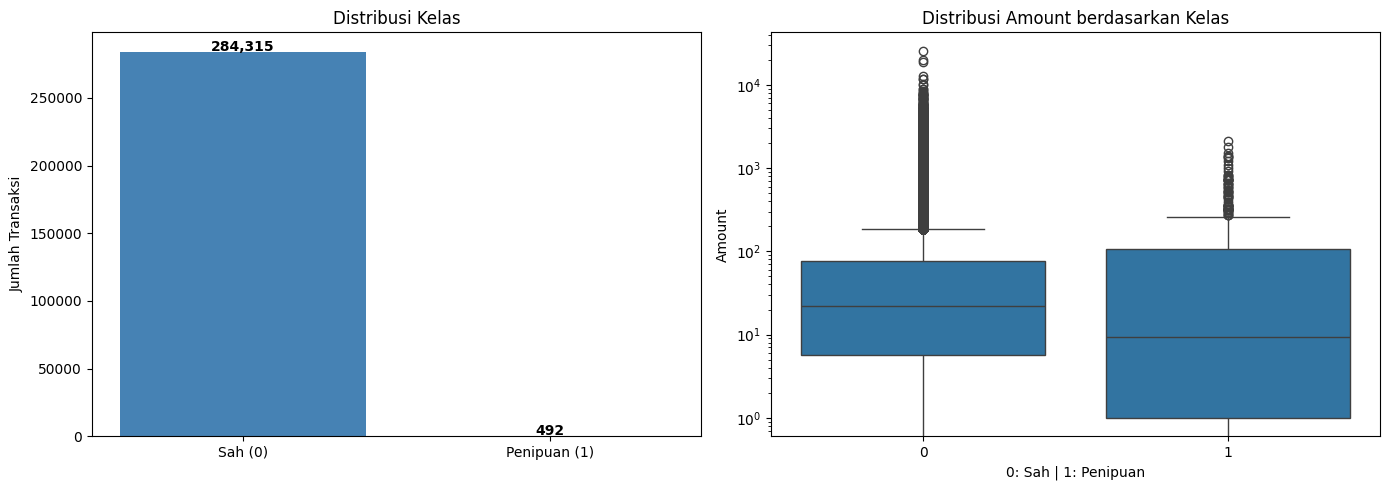

In [6]:
class_counts = df['Class'].value_counts()
print(f"Transaksi Sah (0)      : {class_counts[0]} ({class_counts[0]/len(df)*100:.3f}%)")
print(f"Transaksi Penipuan (1) : {class_counts[1]} ({class_counts[1]/len(df)*100:.3f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi kelas
axes[0].bar(['Sah (0)', 'Penipuan (1)'], [class_counts[0], class_counts[1]],
            color=['steelblue', 'tomato'])
axes[0].set_title('Distribusi Kelas')
axes[0].set_ylabel('Jumlah Transaksi')
for i, v in enumerate([class_counts[0], class_counts[1]]):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Distribusi amount
sns.boxplot(x=df['Class'], y=df['Amount'], ax=axes[1])
axes[1].set_title('Distribusi Amount berdasarkan Kelas')
axes[1].set_xlabel('0: Sah | 1: Penipuan')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

In [7]:
# Handle missing values
if df.isnull().sum().max() > 0:
    df = df.fillna(df.mean())
    print("Missing values diisi dengan mean.")
else:
    print("Tidak ada missing values.")

X = df.drop(['Class', 'Time'], axis=1).values
y = df['Class'].values

print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")

Tidak ada missing values.
Shape X : (284807, 29)
Shape y : (284807,)


SPLIT

In [8]:
from sklearn.model_selection import train_test_split

X_train_full, X_test_final, y_train_full, y_test_final = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Train Set:", X_train_full.shape)
print("Test Set :", X_test_final.shape)
print(f"Fraud -> Train: {sum(y_train_full)} | Test: {sum(y_test_final)}")


Train Set: (227845, 29)
Test Set : (56962, 29)
Fraud -> Train: 394 | Test: 98


In [40]:
LATENT_DIM = 256   # dimensi latent space AutoEncoder

def build_autoencoder(input_dim):
    """AutoEncoder — sama untuk semua model & semua fold."""
    inp     = Input(shape=(input_dim,))
    enc     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(inp)
    latent  = Dense(LATENT_DIM, activation='relu', kernel_regularizer=l2(0.001))(enc)
    dec     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(latent)
    out     = Dense(input_dim, activation='linear')(dec)

    ae      = Model(inputs=inp, outputs=out)
    encoder = Model(inputs=inp, outputs=latent)
    # mse lebih tepat dari binary_crossentropy untuk data StandardScaler
    # (nilainya kontinu & bisa negatif, bukan probabilitas 0-1)
    ae.compile(optimizer=Adam(learning_rate=0.0001), loss='mse')
    return ae, encoder


def extract_hybrid_features(ae, encoder, X_tr, X_te):
    """Gabung: Original Features + Latent Space + MSE Reconstruction Error."""
    mse_tr  = np.mean(np.power(X_tr - ae.predict(X_tr, verbose=0), 2), axis=1, keepdims=True)
    mse_te  = np.mean(np.power(X_te - ae.predict(X_te, verbose=0), 2), axis=1, keepdims=True)
    lat_tr  = encoder.predict(X_tr, verbose=0)
    lat_te  = encoder.predict(X_te, verbose=0)
    return np.hstack((X_tr, lat_tr, mse_tr)), np.hstack((X_te, lat_te, mse_te))


SMOTE_SAMPLING_STRATEGY = 0.25  # rasio minoritas:majoritas setelah resampling
                                 # 0.25 -> fraud:normal jadi ~20:80 (bukan 50:50 penuh)

def apply_smote(X_hybrid_train, y_train, fold_num, sampling_strategy=SMOTE_SAMPLING_STRATEGY):
    """
    SMOTE diterapkan HANYA pada X_train_hybrid (Pilihan B).
    X_test tidak disentuh — tetap distribusi asli.

    sampling_strategy : rasio jumlah sampel minoritas (fraud) dibagi
    majoritas (normal) SETELAH resampling. 1.0 = balance penuh 50:50.
    0.25 = fraud dibuat jadi 20% dari normal (rasio ~80:20), supaya model
    tidak terlalu "berani" menandai fraud (mengurangi false positive).
    """
    sm = SMOTE(random_state=42, k_neighbors=5, sampling_strategy=sampling_strategy)
    X_res, y_res = sm.fit_resample(X_hybrid_train, y_train)
    fraud_before  = int(np.sum(y_train == 1))
    fraud_after   = int(np.sum(y_res == 1))
    normal_after  = int(np.sum(y_res == 0))
    print(f'[Fold {fold_num}] SMOTE (sampling_strategy={sampling_strategy}): '
          f'fraud {fraud_before} → {fraud_after} | normal tetap {normal_after} | '
          f'total train {len(y_train)} → {len(y_res)}')
    return X_res, y_res


RECALL_WEIGHT = 0.6
def find_optimal_threshold(model, X_val, y_val, weight=RECALL_WEIGHT):
    prob = model.predict_proba(X_val)[:,1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)

    j_scores = (weight * tpr) - ((1 - weight) * fpr)
    best_t = thresholds[np.argmax(j_scores)]

    return best_t


print('Fungsi helper siap.')


Fungsi helper siap.


SPLIT DATA 80/20

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {
    'AE + XGBoost'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Random Forest' : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Catboost'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + LightGBM'       : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + MLP'            : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
}

# fold_thresholds menyimpan 5 nilai per model (1 per fold), supaya
# best_thresholds nanti adalah rata-rata sungguhan dari 5 fold.
fold_thresholds = {
    'AE + XGBoost'       : [],
    'AE + Random Forest' : [],
    'AE + CatBoost'       : [],
    'AE + LightGBM'       : [],
    'AE + MLP'            : [],
}

last_fold = {}

for fold_num, (train_idx, val_idx) in enumerate(
    skf.split(X_train_full, y_train_full),
    start=1
):
    print(f'\n{"="*55}')
    print(f'                   FOLD {fold_num} / 5')
    print(f'{"="*55}')

    X_train_raw = X_train_full[train_idx]
    X_val_raw   = X_train_full[val_idx]

    y_train = y_train_full[train_idx]
    y_val   = y_train_full[val_idx]

    # ── Scaling ──────────────────────────────────────────────
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_val   = scaler.transform(X_val_raw)

    print(f'Train: {X_train.shape} | Validation: {X_val.shape}')
    print(f'Fraud di train: {sum(y_train)} | Fraud di validation: {sum(y_val)}')

    # ── AutoEncoder ───────────────────────────────────────────
    # Ditraining hanya dengan data NORMAL (Class=0)
    X_train_normal = X_train[y_train == 0]
    ae, encoder = build_autoencoder(X_train.shape[1])
    ae.fit(
        X_train_normal, X_train_normal,
        epochs=50, batch_size=64, validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    print(f'[Fold {fold_num}] AutoEncoder selesai (training dari data normal saja).')

    # ── Ekstraksi Fitur Hybrid ────────────────────────────────
    X_train_hybrid, X_val_hybrid = extract_hybrid_features(
        ae, encoder, X_train, X_val
    )
    print(f'[Fold {fold_num}] Dimensi hybrid: {X_train_hybrid.shape[1]} fitur')

    # ── Split internal: Fit (training model) vs Threshold-tuning ──
    X_fit_hybrid, X_thresh_hybrid, y_fit, y_thresh = train_test_split(
        X_train_hybrid, y_train,
        test_size=0.2, stratify=y_train, random_state=42
    )
    print(f'[Fold {fold_num}] Split internal -> Fit: {X_fit_hybrid.shape[0]} | '
          f'Threshold-tuning: {X_thresh_hybrid.shape[0]} | Val (evaluasi): {X_val_hybrid.shape[0]}')

    # ── SMOTE ─────────────────────────────────────
    # SMOTE hanya diaplikasikan ke bagian "fit" (BUKAN ke threshold-set, BUKAN ke val)
    X_tr, y_tr = apply_smote(
        X_fit_hybrid,
        y_fit,
        fold_num
    )

    # ════════════════════════════════════════
    # MODEL 1 — AE + XGBoost
    # ════════════════════════════════════════
    m1 = xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=6,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        random_state=42, eval_metric='auc', verbosity=0
    )
    m1.fit(X_tr, y_tr)
    t1    = find_optimal_threshold(m1, X_thresh_hybrid, y_thresh)
    prob1 = m1.predict_proba(X_val_hybrid)[:,1]
    pred1 = (prob1 >= t1).astype(int)
    results['AE + XGBoost']['acc'].append(accuracy_score(y_val, pred1)*100)
    results['AE + XGBoost']['prec'].append(precision_score(y_val, pred1, zero_division=0)*100)
    results['AE + XGBoost']['dr'].append(recall_score(y_val, pred1)*100)
    results['AE + XGBoost']['auc'].append(roc_auc_score(y_val, prob1)*100)
    results['AE + XGBoost']['f1'].append(f1_score(y_val, pred1, zero_division=0)*100)
    fold_thresholds['AE + XGBoost'].append(t1)
    print(f'[Fold {fold_num}] XGBoost      Acc:{results["AE + XGBoost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + XGBoost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + XGBoost"]["auc"][-1]:.2f}% '
          f'(threshold={t1:.3f})')

    # ════════════════════════════════════════
    # MODEL 2 — AE + Random Forest
    # ════════════════════════════════════════
    m2 = RandomForestClassifier(
        n_estimators=200, max_depth=None,
        n_jobs=-1, random_state=42
        # Tidak pakai class_weight karena SMOTE sudah balance
    )
    m2.fit(X_tr, y_tr)
    t2    = find_optimal_threshold(m2, X_thresh_hybrid, y_thresh)
    prob2 = m2.predict_proba(X_val_hybrid)[:, 1]
    pred2 = (prob2 >= t2).astype(int)
    results['AE + Random Forest']['acc'].append(accuracy_score(y_val, pred2)*100)
    results['AE + Random Forest']['prec'].append(precision_score(y_val, pred2, zero_division=0)*100)
    results['AE + Random Forest']['dr'].append(recall_score(y_val, pred2)*100)
    results['AE + Random Forest']['auc'].append(roc_auc_score(y_val, prob2)*100)
    results['AE + Random Forest']['f1'].append(f1_score(y_val, pred2, zero_division=0)*100)
    fold_thresholds['AE + Random Forest'].append(t2)
    print(f'[Fold {fold_num}] Rnd Forest   Acc:{results["AE + Random Forest"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Random Forest"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Random Forest"]["auc"][-1]:.2f}% '
          f'(threshold={t2:.3f})')

    # ════════════════════════════════════════
    # MODEL 3 — AE + Catboost
    # ════════════════════════════════════════
    m3 = CatBoostClassifier(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        random_state=42,
        verbose=0
    )
    m3.fit(X_tr, y_tr)
    t3    = find_optimal_threshold(m3, X_thresh_hybrid, y_thresh)
    prob3 = m3.predict_proba(X_val_hybrid)[:, 1]
    pred3 = (prob3 >= t3).astype(int)
    results['AE + Catboost']['acc'].append(accuracy_score(y_val, pred3)*100)
    results['AE + Catboost']['prec'].append(precision_score(y_val, pred3, zero_division=0)*100)
    results['AE + Catboost']['dr'].append(recall_score(y_val, pred3)*100)
    results['AE + Catboost']['auc'].append(roc_auc_score(y_val, prob3)*100)
    results['AE + Catboost']['f1'].append(f1_score(y_val, pred3, zero_division=0)*100)
    fold_thresholds['AE + CatBoost'].append(t3)
    print(f'[Fold {fold_num}] Catboost          Acc:{results["AE + Catboost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Catboost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Catboost"]["auc"][-1]:.2f}% '
          f'(threshold={t3:.3f})')

    # ════════════════════════════════════════
    # MODEL 4 — AE + LightGBM
    # ════════════════════════════════════════
    m4 = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=6, subsample=0.8, colsample_bytree=0.8,
        is_unbalance=False,   # False karena SMOTE sudah handle
        random_state=42, verbose=-1
    )
    m4.fit(X_tr, y_tr)
    t4    = find_optimal_threshold(m4, X_thresh_hybrid, y_thresh)
    prob4 = m4.predict_proba(X_val_hybrid)[:, 1]
    pred4 = (prob4 >= t4).astype(int)
    results['AE + LightGBM']['acc'].append(accuracy_score(y_val, pred4)*100)
    results['AE + LightGBM']['prec'].append(precision_score(y_val, pred4, zero_division=0)*100)
    results['AE + LightGBM']['dr'].append(recall_score(y_val, pred4)*100)
    results['AE + LightGBM']['auc'].append(roc_auc_score(y_val, prob4)*100)
    results['AE + LightGBM']['f1'].append(f1_score(y_val, pred4, zero_division=0)*100)
    fold_thresholds['AE + LightGBM'].append(t4)
    print(f'[Fold {fold_num}] LightGBM     Acc:{results["AE + LightGBM"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + LightGBM"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + LightGBM"]["auc"][-1]:.2f}% '
          f'(threshold={t4:.3f})')

    # ════════════════════════════════════════
    # MODEL 5 — AE + MLP
    # ════════════════════════════════════════
    m5 = MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation='relu', solver='adam',
        learning_rate_init=0.001, max_iter=200,
        early_stopping=True, validation_fraction=0.1,
        random_state=42
    )
    m5.fit(X_tr, y_tr)
    t5    = find_optimal_threshold(m5, X_thresh_hybrid, y_thresh)
    prob5 = m5.predict_proba(X_val_hybrid)[:, 1]
    pred5 = (prob5 >= t5).astype(int)
    results['AE + MLP']['acc'].append(accuracy_score(y_val, pred5)*100)
    results['AE + MLP']['prec'].append(precision_score(y_val, pred5, zero_division=0)*100)
    results['AE + MLP']['dr'].append(recall_score(y_val, pred5)*100)
    results['AE + MLP']['auc'].append(roc_auc_score(y_val, prob5)*100)
    results['AE + MLP']['f1'].append(f1_score(y_val, pred5, zero_division=0)*100)
    fold_thresholds['AE + MLP'].append(t5)
    print(f'[Fold {fold_num}] MLP          Acc:{results["AE + MLP"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + MLP"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + MLP"]["auc"][-1]:.2f}% '
          f'(threshold={t5:.3f})')

    if fold_num == 5:
        last_fold = {
            'AE + XGBoost'       : (y_val, pred1, prob1),
            'AE + Random Forest' : (y_val, pred2, prob2),
            'AE + Catboost'      : (y_val, pred3, prob3),
            'AE + LightGBM'      : (y_val, pred4, prob4),
            'AE + MLP'           : (y_val, pred5, prob5),
        }

print('\n' + '='*55)
print('Training & evaluasi selesai untuk semua fold.')
print('='*55)



                   FOLD 1 / 5
Train: (182276, 29) | Validation: (45569, 29)
Fraud di train: 316 | Fraud di validation: 78
[Fold 1] AutoEncoder selesai (training dari data normal saja).
[Fold 1] Dimensi hybrid: 286 fitur
[Fold 1] Split internal -> Fit: 145820 | Threshold-tuning: 36456 | Val (evaluasi): 45569
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 253 → 36391 | normal tetap 145567 | total train 145820 → 181958
[Fold 1] XGBoost      Acc:85.18% DR:98.72% AUC:99.27% (threshold=0.001)
[Fold 1] Rnd Forest   Acc:77.61% DR:98.72% AUC:98.97% (threshold=0.005)
[Fold 1] Catboost          Acc:87.97% DR:98.72% AUC:98.83% (threshold=0.005)
[Fold 1] LightGBM     Acc:85.67% DR:98.72% AUC:99.16% (threshold=0.001)
[Fold 1] MLP          Acc:71.33% DR:94.87% AUC:96.71% (threshold=0.000)

                   FOLD 2 / 5
Train: (182276, 29) | Validation: (45569, 29)
Fraud di train: 315 | Fraud di validation: 79
[Fold 2] AutoEncoder selesai (training dari data normal saja).
[Fold 2] Dimensi hybrid: 286

In [11]:
print("\n" + "="*60)
print("AVERAGE 5-FOLD CROSS VALIDATION RESULTS")
print("="*60)

for model_name, metrics in results.items():
    print(f"\n{model_name}")
    print(f"Accuracy : {np.mean(metrics['acc']):.4f} ± {np.std(metrics['acc']):.4f}")
    print(f"Recall   : {np.mean(metrics['dr']):.4f} ± {np.std(metrics['dr']):.4f}")
    print(f"AUC      : {np.mean(metrics['auc']):.4f} ± {np.std(metrics['auc']):.4f}")


AVERAGE 5-FOLD CROSS VALIDATION RESULTS

AE + XGBoost
Accuracy : 90.5177 ± 4.2240
Recall   : 94.4271 ± 3.1576
AUC      : 98.2505 ± 0.8140

AE + Random Forest
Accuracy : 90.4259 ± 6.9196
Recall   : 94.9335 ± 2.8823
AUC      : 97.8324 ± 1.2991

AE + Catboost
Accuracy : 88.9556 ± 4.3422
Recall   : 93.9208 ± 2.8136
AUC      : 98.0638 ± 0.8771

AE + LightGBM
Accuracy : 90.3935 ± 4.2125
Recall   : 94.4271 ± 2.9477
AUC      : 98.0668 ± 0.7658

AE + MLP
Accuracy : 82.7747 ± 10.5804
Recall   : 91.1263 ± 3.2860
AUC      : 95.2764 ± 0.8282


In [26]:
# PERBAIKAN: fold_thresholds sekarang berisi 5 nilai per model (1 per fold),
# jadi best_thresholds di bawah ini adalah RATA-RATA SUNGGUHAN dari 5 fold,
# bukan cuma nilai dari fold terakhir seperti sebelumnya.
best_thresholds = {
    k: np.mean(v)
    for k, v in fold_thresholds.items()
}

print("Threshold rata-rata (dari 5 fold):")
for k, v in best_thresholds.items():
    per_fold = ", ".join(f"{x:.3f}" for x in fold_thresholds[k])
    print(f"  {k:<20}: {v:.4f}   (per-fold: {per_fold})")

Threshold rata-rata (dari 5 fold):
  AE + XGBoost        : 0.0021   (per-fold: 0.001, 0.002, 0.001, 0.001, 0.005)
  AE + Random Forest  : 0.0150   (per-fold: 0.005, 0.030, 0.015, 0.010, 0.015)
  AE + CatBoost       : 0.0058   (per-fold: 0.005, 0.015, 0.002, 0.005, 0.002)
  AE + LightGBM       : 0.0015   (per-fold: 0.001, 0.002, 0.000, 0.002, 0.003)
  AE + MLP            : 0.0000   (per-fold: 0.000, 0.000, 0.000, 0.000, 0.000)


In [41]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_full)
X_test_scaled  = scaler.transform(X_test_final)


In [42]:
X_train_normal = X_train_scaled[y_train_full == 0]

ae, encoder = build_autoencoder(X_train_scaled.shape[1])

ae.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - loss: 0.4334 - val_loss: 0.1841
Epoch 2/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - loss: 0.1284 - val_loss: 0.0926
Epoch 3/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - loss: 0.0782 - val_loss: 0.0709
Epoch 4/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 23s 7ms/step - loss: 0.0639 - val_loss: 0.0608
Epoch 5/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 24s 7ms/step - loss: 0.0575 - val_loss: 0.0538
Epoch 6/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - loss: 0.0535 - val_loss: 0.0507
Epoch 7/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 24s 8ms/step - loss: 0.0503 - val_loss: 0.0474
Epoch 8/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 24s 7ms/step - loss: 0.0478 - val_loss: 0.0473
Epoch 9/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 24s 7ms/step - loss: 0.0455 - val_loss: 0.0442
Epoch 10/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 23s 7ms/step - loss: 0.0444 - val_loss: 0.0421
Epoch 11/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 24s 7ms/step - loss: 0.0428 - val_loss: 0.0419
Epoch 12/50
3199/31

In [43]:
X_train_hybrid, X_test_hybrid = extract_hybrid_features(
    ae,
    encoder,
    X_train_scaled,
    X_test_scaled
)


In [44]:
X_train_smote, y_train_smote = apply_smote(
    X_train_hybrid,
    y_train_full,
    fold_num=0
)

[Fold 0] SMOTE (sampling_strategy=0.25): fraud 394 → 56862 | normal tetap 227451 | total train 227845 → 284313


In [45]:
m1 = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    verbosity=0
)
m1.fit(X_train_smote, y_train_smote)

m2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    random_state=42
)
m2.fit(X_train_smote, y_train_smote)

m3 = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    random_state=42,
    verbose=0
)
m3.fit(X_train_smote, y_train_smote)

m4 = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    is_unbalance=False,
    random_state=42,
    verbose=-1
)
m4.fit(X_train_smote, y_train_smote)

m5 = MLPClassifier(
    hidden_layer_sizes=(256,128,64),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
m5.fit(X_train_smote, y_train_smote)

,hidden_layer_sizes,"(256, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,42


In [46]:
final_models = {
    "AE + XGBoost": m1,
    "AE + Random Forest": m2,
    "AE + CatBoost": m3,
    "AE + LightGBM": m4,
    "AE + MLP": m5
}

In [47]:
from sklearn.metrics import classification_report

all_predictions = {}

print("\nFINAL HOLD-OUT TEST RESULTS")
print("="*60)

for name, model in final_models.items():

    prob = model.predict_proba(X_test_hybrid)[:,1]

    threshold = best_thresholds[name]   # rata-rata threshold dari 5 fold CV

    pred = (prob >= threshold).astype(int)

    # simpan hasil prediksi (dict, dipakai cell confusion matrix/ROC/PR di bawah)
    all_predictions[name] = {'pred': pred, 'prob': prob}

    acc = accuracy_score(y_test_final, pred)*100
    dr  = recall_score(y_test_final, pred)*100
    auc = roc_auc_score(y_test_final, prob)*100

    print(
        f"{name:<20}"
        f" Acc={acc:.2f}%"
        f" | DR={dr:.2f}%"
        f" | AUC={auc:.2f}%"
    )



FINAL HOLD-OUT TEST RESULTS
AE + XGBoost         Acc=88.67% | DR=93.88% | AUC=97.75%
AE + Random Forest   Acc=93.66% | DR=94.90% | AUC=97.79%
AE + CatBoost        Acc=85.34% | DR=95.92% | AUC=98.43%
AE + LightGBM        Acc=84.46% | DR=93.88% | AUC=97.32%
AE + MLP             Acc=95.56% | DR=90.82% | AUC=97.46%


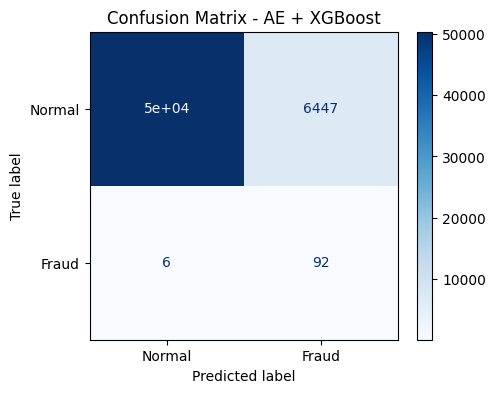

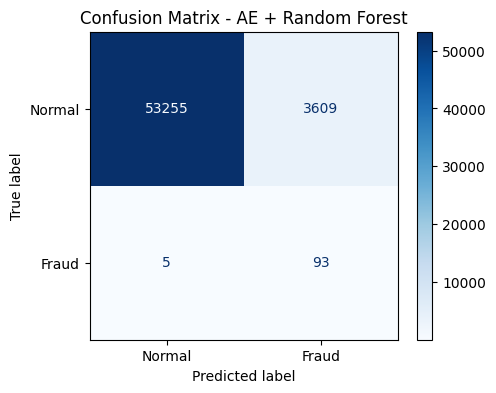

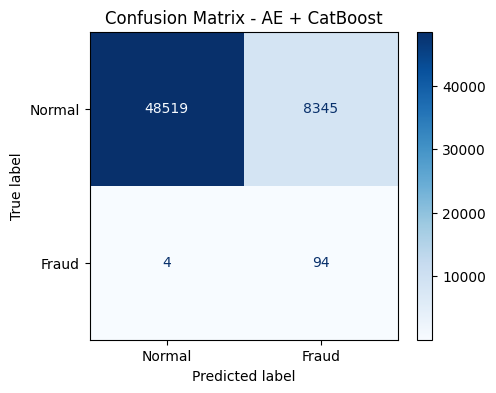

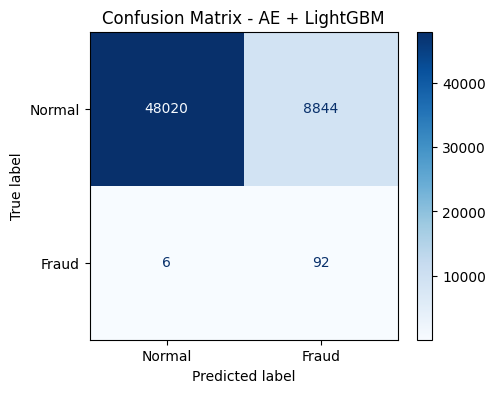

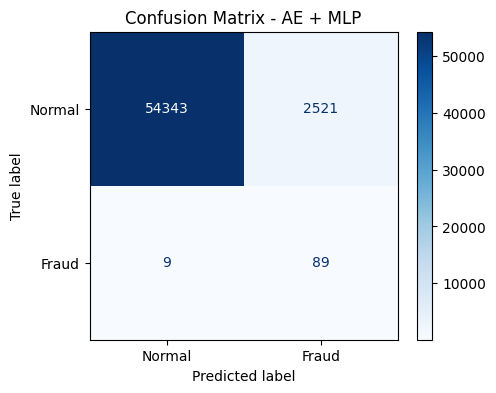

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, data in all_predictions.items():

    pred = data['pred']

    cm = confusion_matrix(y_test_final, pred)

    fig, ax = plt.subplots(figsize=(5,4))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Normal','Fraud']
    )

    disp.plot(ax=ax, cmap='Blues')

    plt.title(f'Confusion Matrix - {name}')
    plt.show()

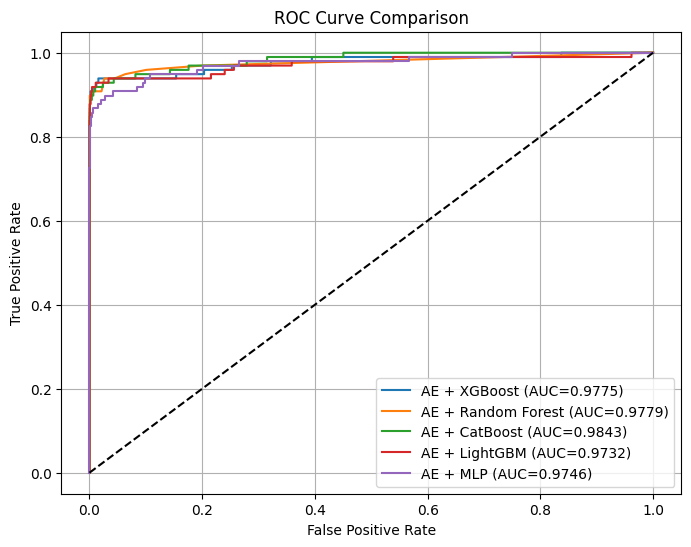

In [49]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    fpr, tpr, _ = roc_curve(y_test_final, prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC={roc_auc:.4f})'
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)

plt.show()

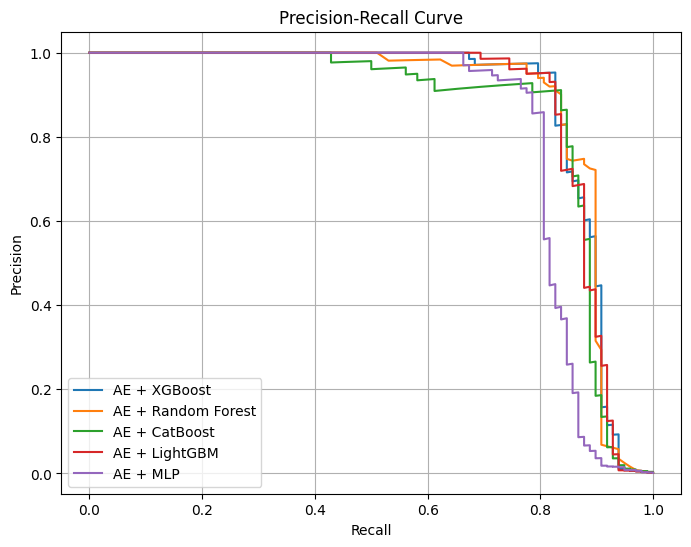

In [50]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    precision, recall, _ = precision_recall_curve(
        y_test_final,
        prob
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)

plt.show()

In [51]:
for name, data in all_predictions.items():

    pred = data['pred']

    print("\n" + "="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test_final,
            pred,
            digits=4
        )
    )



AE + XGBoost
              precision    recall  f1-score   support

           0     0.9999    0.8866    0.9399     56864
           1     0.0141    0.9388    0.0277        98

    accuracy                         0.8867     56962
   macro avg     0.5070    0.9127    0.4838     56962
weighted avg     0.9982    0.8867    0.9383     56962


AE + Random Forest
              precision    recall  f1-score   support

           0     0.9999    0.9365    0.9672     56864
           1     0.0251    0.9490    0.0489        98

    accuracy                         0.9366     56962
   macro avg     0.5125    0.9428    0.5081     56962
weighted avg     0.9982    0.9366    0.9656     56962


AE + CatBoost
              precision    recall  f1-score   support

           0     0.9999    0.8532    0.9208     56864
           1     0.0111    0.9592    0.0220        98

    accuracy                         0.8534     56962
   macro avg     0.5055    0.9062    0.4714     56962
weighted avg     0.9982  

In [52]:
summary = []

for name, data in all_predictions.items():

    pred = data['pred']
    prob = data['prob']

    summary.append([
        name,
        accuracy_score(y_test_final,pred)*100,
        precision_score(y_test_final,pred)*100,
        recall_score(y_test_final,pred)*100,
        f1_score(y_test_final,pred)*100,
        roc_auc_score(y_test_final,prob)*100
    ])

result_df = pd.DataFrame(
    summary,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1',
        'AUC'
    ]
)

result_df.sort_values(
    by='Recall',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,AUC
2,AE + CatBoost,85.342860,1.113876,95.918367,2.202179,98.429120
1,AE + Random Forest,93.655419,2.512156,94.897959,4.894737,97.789570
0,AE + XGBoost,88.671395,1.406943,93.877551,2.772337,97.747974
3,AE + LightGBM,84.463326,1.029543,93.877551,2.036750,97.315094
4,AE + MLP,95.558442,3.409962,90.816327,6.573117,97.462277
